# Formative 2 - Multimodal Data Preprocessing
## Part 3: Voice Sample Collection, Augmentation and Feature Extraction

**Project component:** input data for the voiceprint verification model (the check that approves a transaction).

### Objectives
1. Load every member's recordings of the two phrases, *"Yes, approve"* and *"Confirm transaction"*.
2. Clean them so differences between phones and recording habits do not leak into the features.
3. Display each sample as a waveform and a spectrogram, and interpret them.
4. Apply six augmentations per sample.
5. Extract MFCC, spectral roll-off, energy and related features, and save them to `datasets/audio_features.csv`.

All processing code lives in [`src/audio_pipeline.py`](../src/audio_pipeline.py). The command-line demo reuses the same
functions on a new recording.

### Data layout
```
data/audio/<member>/<member>_<phrase>_<take>.<any audio extension>
```
The folder name is the speaker label. The phrase and take are read from the file name, and variants such as
`Yes Approve 2` or `confirm-transaction` are accepted.

### Supported formats
Clips can be WAV, M4A, AAC, MP3, MP4, OGG, OPUS, FLAC, WEBM, AMR, 3GP, AIFF or WMA, as phones produce them.
[`src/media_io.py`](../src/media_io.py) decodes each file by its *content*, so even a phone recording renamed to `.wav`
works. WAV, FLAC and OGG are read with `soundfile`; everything else is decoded with PyAV, which ships its own FFmpeg in
the pip package, so no system program has to be installed on Windows, macOS, Linux or Colab. Running
`python -m src.media_io` converts the repository's clips to standard 16-bit mono WAV (44.1 kHz) and fixes their names.
Exact duplicate files (the same take saved twice) are skipped with a warning.

## 1. Environment setup

This cell makes the notebook run anywhere without manual steps:

* **Locally** (Jupyter, VS Code, PyCharm on Windows, macOS or Linux) it finds the repository folder from wherever the
  notebook is opened.
* **On Google Colab, Kaggle or any other hosted notebook** it clones the repository first.
* It installs only the packages from `requirements.txt` that are missing, so an existing setup is never changed.

All file paths are relative to the repository, so nothing needs to be edited before running.

In [1]:
import importlib
import os
import subprocess
import sys
import warnings
from pathlib import Path

# The GitHub repository this notebook belongs to (only used when the notebook is opened on its own).
REPO_URL = os.environ.get("F2_REPO_URL", "https://github.com/mutaganzwa-desire/multimodal_data_preprocessing.git")
REQUIRED_FILES = ["app.py", "src/environment.py", "src/media_io.py", "src/verification.py"]


def missing_files(folder: Path) -> list:
    return [f for f in REQUIRED_FILES if not (folder / f).exists()]


def find_repo_root() -> Path:
    """Return the repository folder, cloning or updating it when needed.

    * Opened from inside a clone (Jupyter, VS Code or PyCharm on Windows, macOS or Linux): that clone is used.
    * Opened on its own (Google Colab, Kaggle, a downloaded .ipynb): the repository is cloned next to the
      notebook, and an older copy left there by a previous run is updated with `git pull`.
    """
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if not missing_files(folder):
            return folder
    target = Path.cwd() / "multimodal_data_preprocessing"
    if (target / ".git").exists():
        subprocess.run(["git", "-C", str(target), "pull", "-q", "--ff-only"], check=False)
    elif not target.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL, str(target)], check=True)
    missing = missing_files(target)
    if missing:
        raise FileNotFoundError(
            f"The repository copy in {target} has no {', '.join(missing)}: it is older than this notebook. "
            "Push the latest commits to GitHub, delete that folder (on Colab: Runtime > Disconnect and delete "
            "runtime), and run this cell again."
        )
    return target


REPO_ROOT = find_repo_root()
os.chdir(REPO_ROOT)
sys.path.insert(0, str(REPO_ROOT))
for name in [m for m in sys.modules if m == "src" or m.startswith("src.")]:
    del sys.modules[name]  # forget modules imported from another copy in an earlier run
importlib.invalidate_caches()

from src.environment import ensure_packages

ensure_packages()  # installs only the packages that are missing, then does nothing on later runs
warnings.filterwarnings("ignore", category=FutureWarning)
print("Repository folder:", REPO_ROOT.name)

All required packages are available.
Repository folder: multimodal_data_preprocessing


In [2]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, display
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from src import audio_pipeline as ap
from src import media_io

SR = ap.SAMPLE_RATE
# Newer librosa/numba builds print a harmless cast warning inside pitch_shift;
# the output is checked for NaN and infinite values in section 8.
warnings.filterwarnings("ignore", message="invalid value encountered in cast")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 80

## 2. Clip inventory

Every member needs both phrases, ideally recorded twice. `real_format` shows the format found inside each file.

In [3]:
clips = ap.find_clips()
members = sorted(clips["member"].unique())
raw = {row.path: ap.load_audio(row.path) for row in clips.itertuples()}
clean = {path: ap.clean(y) for path, y in raw.items()}

inventory = clips.assign(
    file=clips["path"].map(lambda p: p.name),
    extension=clips["path"].map(lambda p: p.suffix.lstrip(".")),
    real_format=clips["path"].map(media_io.detect_format),
    recorded_s=clips["path"].map(lambda p: round(len(raw[p]) / SR, 2)),
    speech_s=clips["path"].map(lambda p: round(len(clean[p]) / SR, 2)),
).drop(columns="path")
display(inventory)
display(pd.crosstab(clips["member"], clips["phrase"]))

,member,phrase,take,file,extension,real_format,recorded_s,speech_s
0,alain,confirm_transaction,1,alain_confirm_transaction_1.wav,wav,wav,4.03,1.63
1,alain,confirm_transaction,2,alain_confirm_transaction_2.wav,wav,wav,4.01,1.60
2,alain,yes_approve,1,alain_yes_approve_1.wav,wav,wav,4.01,0.93
3,alain,yes_approve,2,alain_yes_approve_2.wav,wav,wav,4.07,1.47
4,arnold,confirm_transaction,1,arnold_confirm_transaction_1.wav,wav,wav,3.11,1.66
5,arnold,confirm_transaction,2,arnold_confirm_transaction_2.wav,wav,wav,2.72,1.47
6,arnold,yes_approve,1,arnold_yes_approve_1.wav,wav,wav,2.72,2.17
7,arnold,yes_approve,2,arnold_yes_approve_2.wav,wav,wav,3.48,1.18
8,desire,confirm_transaction,1,desire_confirm_transaction_1.wav,wav,wav,2.81,1.47
9,desire,confirm_transaction,2,desire_confirm_transaction_2.wav,wav,wav,2.76,1.41


phrase,confirm_transaction,yes_approve
member,,
alain,2,2
arnold,2,2
desire,2,2
ivan,1,1


**Interpretation:** 14 usable recordings from four speakers. Alain, Arnold and Desire recorded each phrase twice. Arnold's four clips were uploaded to `data/audio/` without a member folder, with names like `Yes Approved.wav` and `Confirm transaction-1.wav`; they were moved to `data/audio/arnold/` and renamed, since the folder name is the speaker label. Ivan's files arrived as MP4/AAC phone recordings renamed to `.wav`; `python -m src.media_io` converted them to real WAV. His `_2` files were byte-for-byte copies of his `_1` files (the pipeline flagged and skipped them), so they were deleted and Ivan has one take per phrase.

Recording lengths differ by phone and habit (Alain 4.0 s, the others 2.6 to 3.5 s). After cleaning, the spoken part is 0.9 to 2.2 s, so clip length reflects how quickly the phrase was spoken rather than how long the recorder ran.

## 3. Cleaning: keep only the spoken phrase

The members recorded on different phones, in different formats, with different silence before and after speaking
and different loudness. If left in, a model could tell speakers apart by **clip length or volume** instead of by voice.
Each clip is therefore:

1. Read as mono and resampled to 16 kHz, the same rate for every device.
2. Split into sound regions. A frame counts as sound when it is within 30 dB of the loudest part **and** at least 12 dB
   above the recording's own noise floor (its quietest 10% of frames). The second rule matters for phones with a steady
   background hum, where the hum itself is within 30 dB of the voice.
3. Regions separated by less than 0.4 s (gaps between words) are joined. The joined region with the most energy is
   kept, which drops silence and stray clicks or breaths.
4. Peak normalised to 0.95.

The shaded part of each waveform below is what is kept.

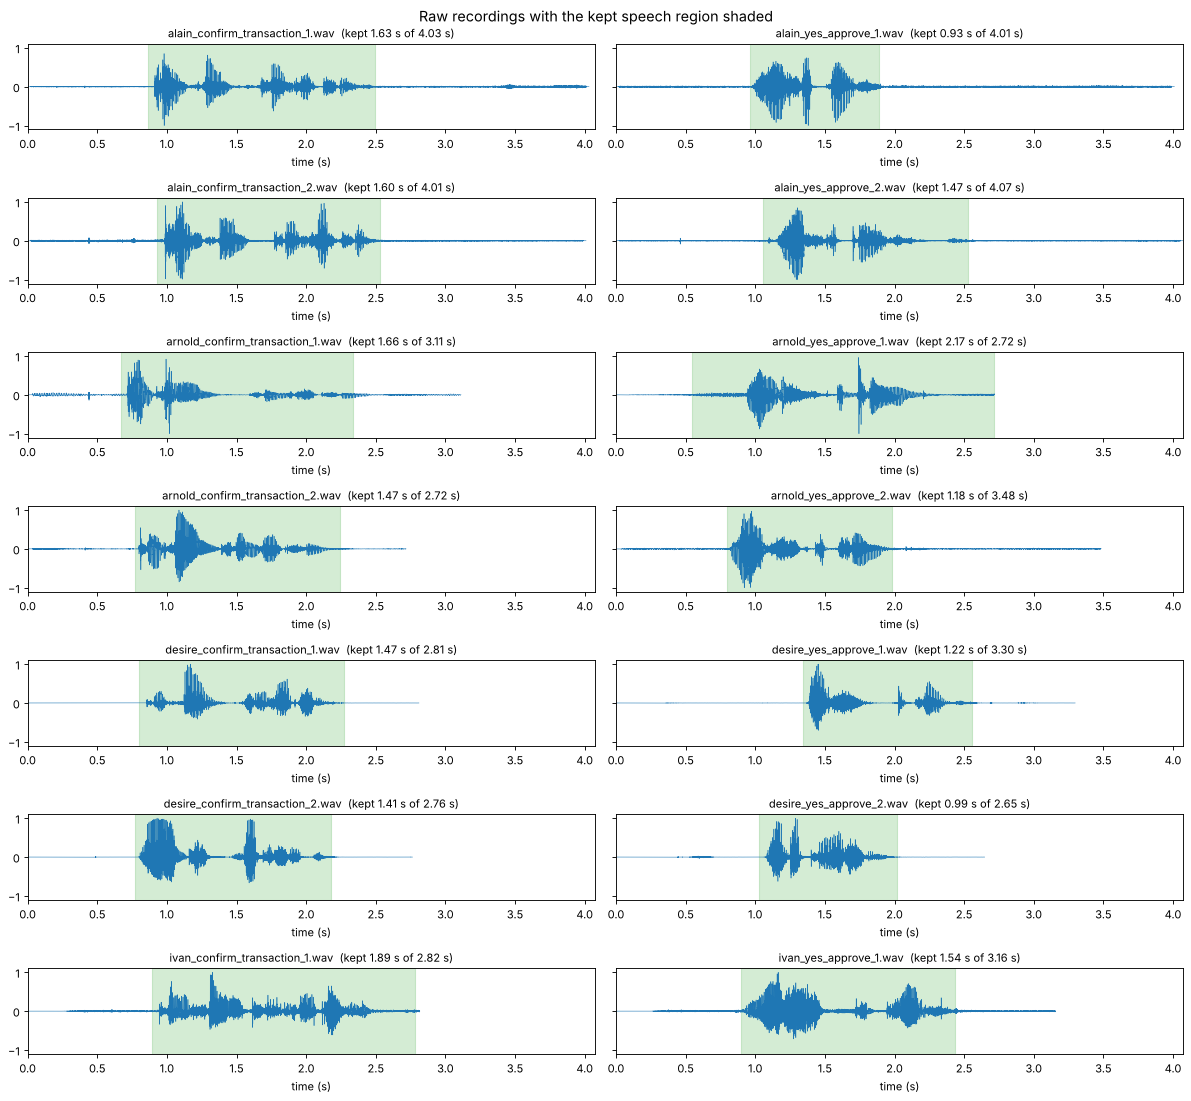

In [4]:
phrases = sorted(clips["phrase"].unique())
n_rows = clips.groupby("phrase").size().max()
fig, axes = plt.subplots(n_rows, len(phrases), figsize=(7.5 * len(phrases), 2.0 * n_rows), sharey=True, squeeze=False)
for c, phrase in enumerate(phrases):
    for r, row in enumerate(clips[clips["phrase"] == phrase].sort_values(["member", "take"]).itertuples()):
        ax = axes[r, c]
        y = raw[row.path]
        start, end = ap.speech_interval(y)
        t = np.arange(len(y)) / SR
        ax.plot(t, y / (np.abs(y).max() or 1), lw=0.5, color="tab:blue")
        ax.axvspan(start / SR, end / SR, color="tab:green", alpha=0.2)
        ax.set_title(f"{row.path.name}  (kept {(end - start) / SR:.2f} s of {len(y) / SR:.2f} s)", fontsize=10)
        ax.set_xlim(0, max(len(v) for v in raw.values()) / SR)
        ax.set_xlabel("time (s)")
    for ax in axes[clips["phrase"].eq(phrase).sum():, c]:
        ax.axis("off")
fig.suptitle("Raw recordings with the kept speech region shaded", fontsize=13)
fig.tight_layout()
plt.show()

**Interpretation:** the green region covers the phrase in every clip and leaves out the silence before and after it. In `alain_confirm_transaction_1.wav` and `alain_yes_approve_1.wav` a faint sound around 3.5 s, well after the phrase ends, is correctly excluded. `arnold_confirm_transaction_1.wav` shows why the noise-floor rule was added: a steady hum runs through the whole file, only about 20 dB below the voice, so a fixed 30 dB rule kept all 3.1 s, hum included. With the adaptive rule only the 1.7 s of speech is kept. The same rule trims the background hiss after Ivan's phrases (now 1.9 s and 1.5 s instead of 2.5 s and 2.1 s). For speakers with a quiet background (Desire, Arnold's other takes) nothing changes.

## 4. Waveforms per member

Cleaned clips, all on the same time and amplitude scale.

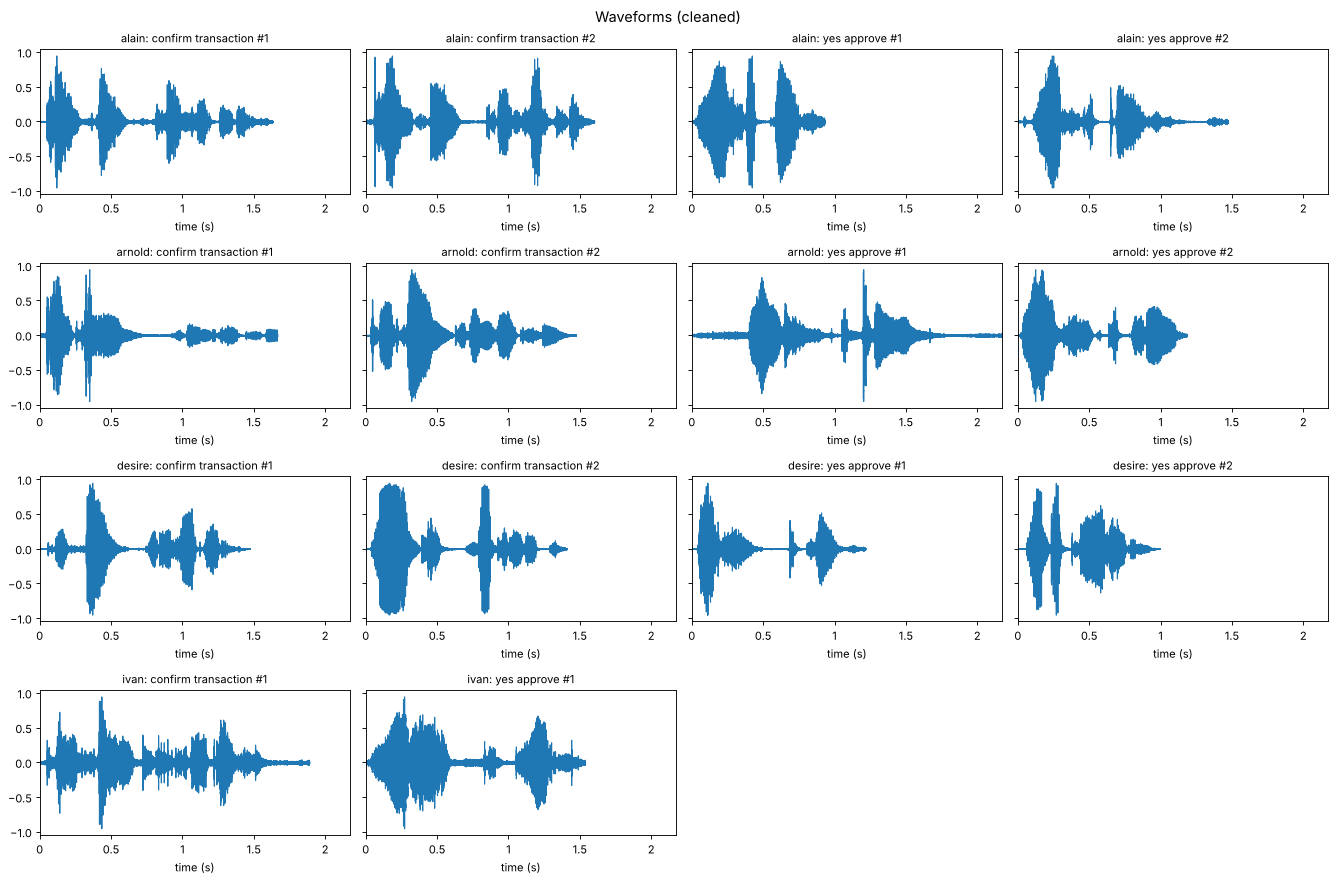

In [5]:
order = clips.sort_values(["member", "phrase", "take"])
n_cols = order.groupby("member").size().max()
longest = max(len(y) for y in clean.values()) / SR

fig, axes = plt.subplots(len(members), n_cols, figsize=(4.2 * n_cols, 2.8 * len(members)), sharey=True,
                         squeeze=False)
for r, member in enumerate(members):
    for c, row in enumerate(order[order["member"] == member].itertuples()):
        ax = axes[r, c]
        librosa.display.waveshow(clean[row.path], sr=SR, ax=ax, color="tab:blue")
        ax.set_title(f"{member}: {row.phrase.replace('_', ' ')} #{row.take}", fontsize=10)
        ax.set_xlim(0, longest)
        ax.set_xlabel("time (s)")
    for ax in axes[r, (order["member"] == member).sum():]:
        ax.axis("off")  # member with fewer clips
fig.suptitle("Waveforms (cleaned)", fontsize=13)
fig.tight_layout()
plt.show()

**Interpretation:** "Confirm transaction" shows four or five bursts, one per syllable (con-firm-trans-ac-tion), while "Yes, approve" shows a strong burst for "yes", a short pause, then "approve". Desire speaks fastest (1.0 to 1.5 s per phrase); Alain, Arnold and Ivan take 0.9 to 2.2 s. Desire's second "confirm transaction" starts with a very loud, flat-looking first word: the phone's automatic level control compressed it. Its peak is 0.85 of full scale, so it is not clipped and is kept. Alain's `confirm_transaction #2` contains one sharp click near its start, and Arnold's `yes_approve #1` one sharp click in the middle; single clicks barely affect the frame-averaged features.

## 5. Spectrograms per member

Mel spectrograms in decibels. Time runs left to right, pitch from bottom to top, and brighter means louder.

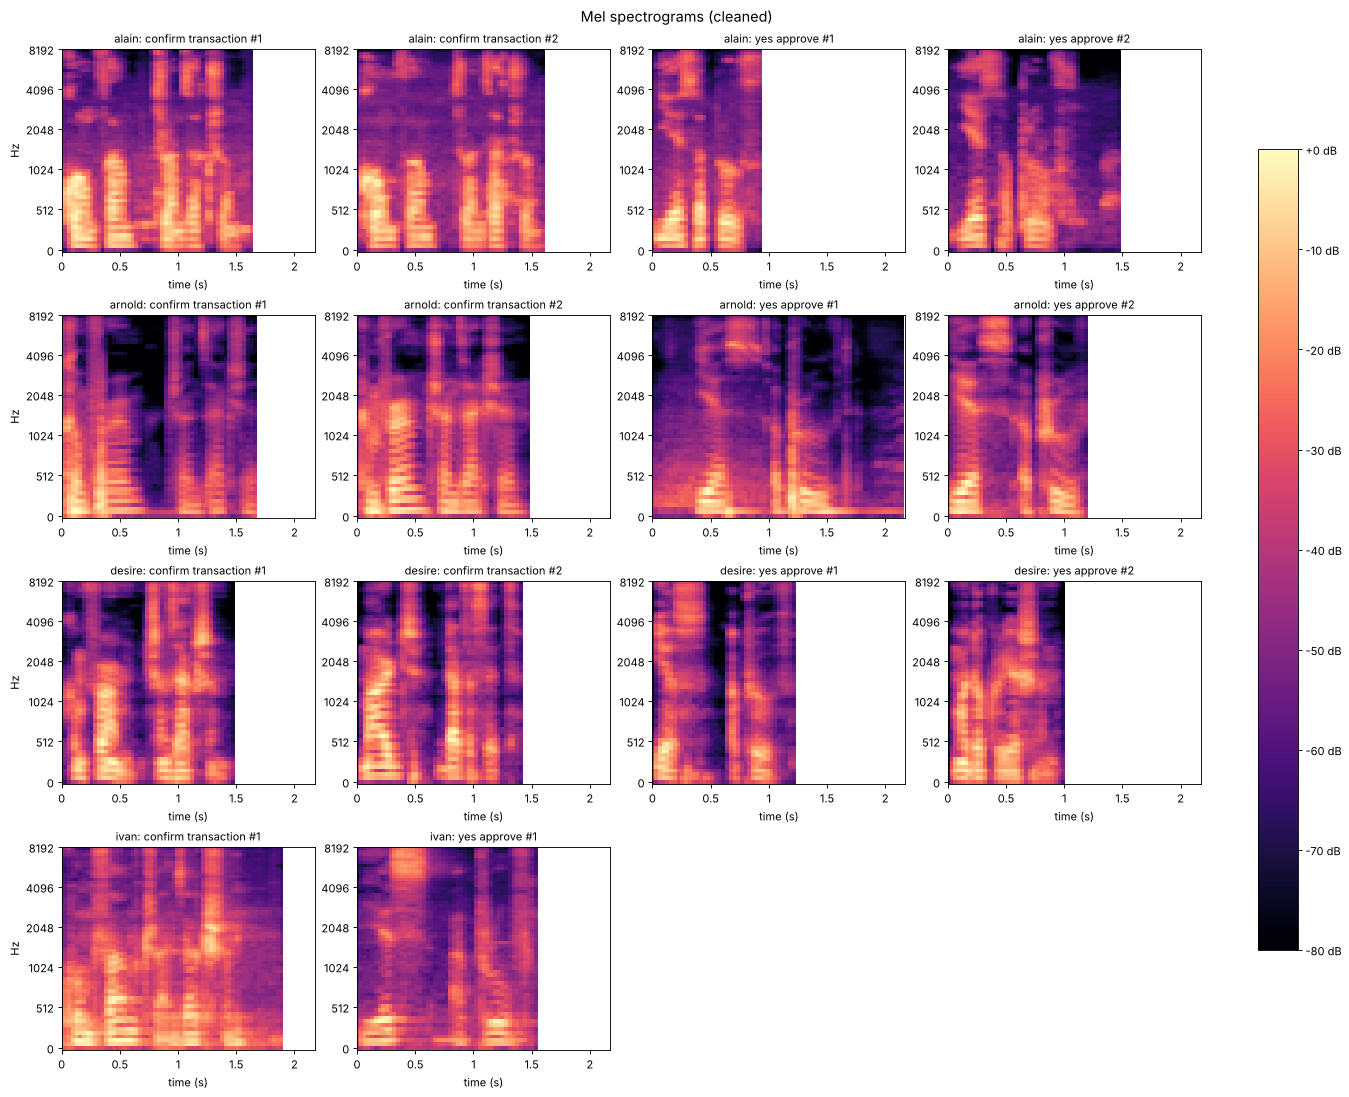

In [6]:
fig, axes = plt.subplots(len(members), n_cols, figsize=(4.2 * n_cols, 3.4 * len(members)), layout="constrained",
                         squeeze=False)
for r, member in enumerate(members):
    for c, row in enumerate(order[order["member"] == member].itertuples()):
        ax = axes[r, c]
        mel = librosa.feature.melspectrogram(y=clean[row.path], sr=SR, n_mels=64)
        img = librosa.display.specshow(librosa.power_to_db(mel, ref=np.max), sr=SR, x_axis="time",
                                       y_axis="mel", ax=ax, cmap="magma", vmin=-80, vmax=0)
        ax.set_title(f"{member}: {row.phrase.replace('_', ' ')} #{row.take}", fontsize=10)
        ax.set_xlim(0, longest)
        ax.set_xlabel("time (s)")
        ax.set_ylabel("Hz" if c == 0 else "")
    for ax in axes[r, (order["member"] == member).sum():]:
        ax.axis("off")
fig.colorbar(img, ax=axes.ravel().tolist(), format="%+2.0f dB", shrink=0.8)
fig.suptitle("Mel spectrograms (cleaned)", fontsize=13)
plt.show()

**Interpretation:** the bright horizontal bands below about 1 kHz are the harmonics and formants of the vowels, and the vertical streaks reaching above 4 kHz are consonants such as "s" and "f". For the same phrase every speaker shows the same syllable pattern (the content), while the spacing and brightness of the low bands differ (the voice), which is what MFCCs capture. Arnold's energy sits lowest: his spectrograms are darkest above 2 kHz, matching his low spectral centroid (about 1,670 Hz on the original recordings, against about 2,000 Hz for the others).

One difference has nothing to do with the voice: between words Desire's clips drop to black (a noise floor of about -63 to -73 dBFS), while Alain's, Ivan's and Arnold's keep a purple background of room noise, brightest for Ivan. That comes from the different phones and their recording formats: Desire's phone removed quiet background noise. The `background_noise` augmentation below partly hides this difference, and it is listed as a limitation in the summary.

Listen to one cleaned clip per member:

In [7]:
for member in members:
    row = order[order["member"] == member].iloc[0]
    print(f"{member}: {row['path'].name}")
    display(Audio(clean[row["path"]], rate=SR))

alain: alain_confirm_transaction_1.wav


arnold: arnold_confirm_transaction_1.wav


desire: desire_confirm_transaction_1.wav


ivan: ivan_confirm_transaction_1.wav


## 6. Augmentation

Each cleaned clip gets **6 augmentations** plus the original, giving 7 versions per recording. Each one imitates a way the
same person may sound at login time:

| Augmentation | Imitates |
|---|---|
| `pitch_up_2st`, `pitch_down_2st` | voice slightly higher or lower (tired, excited, a cold) |
| `time_stretch_fast`, `time_stretch_slow` | speaking 15% faster or slower |
| `background_noise` | a noisy room (white noise at 20 dB SNR) |
| `gain_down_6db` | holding the phone further away |

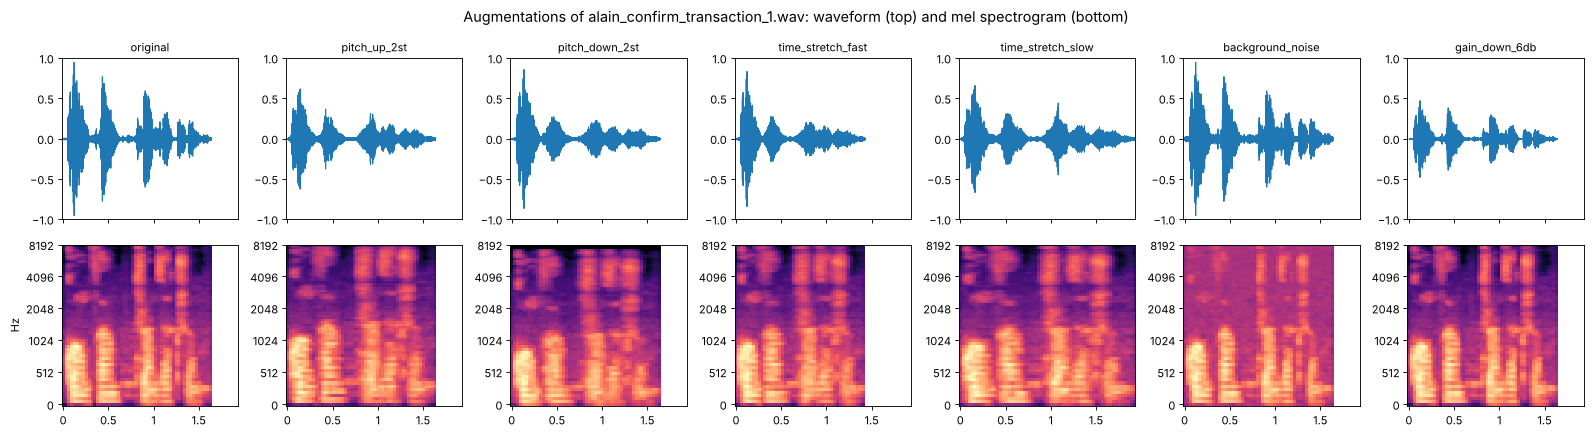

original


pitch_up_2st


pitch_down_2st


time_stretch_fast


time_stretch_slow


background_noise


gain_down_6db


In [8]:
example = order.iloc[0]["path"]
versions = ap.augment(clean[example])

fig, axes = plt.subplots(2, len(versions), figsize=(20, 5.5), sharex=True)
for c, (name, y) in enumerate(versions.items()):
    librosa.display.waveshow(y, sr=SR, ax=axes[0, c], color="tab:blue")
    axes[0, c].set_ylim(-1, 1)
    axes[0, c].set_title(name, fontsize=10)
    mel = librosa.feature.melspectrogram(y=y, sr=SR, n_mels=64)
    librosa.display.specshow(librosa.power_to_db(mel, ref=np.max), sr=SR, x_axis="time", y_axis="mel",
                             ax=axes[1, c], cmap="magma", vmin=-80, vmax=0)
    for ax in axes[:, c]:
        ax.set_xlabel("")
        if c:
            ax.set_ylabel("")
fig.suptitle(f"Augmentations of {example.name}: waveform (top) and mel spectrogram (bottom)", fontsize=13)
fig.tight_layout()
plt.show()

for name, y in versions.items():
    print(name)
    display(Audio(y, rate=SR, normalize=False))

**Interpretation:** the pitch shifts move the harmonic bands up or down without changing the timing. Time stretching changes the length (1.42 s and 1.92 s instead of 1.63 s) without changing the pitch. Background noise fills the gaps between words and the top of the spectrogram with an even floor. The gain change only lowers the waveform, so its spectrogram (shown relative to its own peak) looks the same and only the energy features, `rms_energy_*` and `mfcc_1_*`, change. Together they teach the voiceprint model that a slightly different-sounding version of the same person is still that person.

## 7. Feature extraction

Each version is summarised as 50 fixed-length features. Features are computed per 32 ms frame and then
summarised over time with the mean and standard deviation, so clips of any length give the same columns.

| Feature | Columns | What it captures |
|---|---|---|
| MFCC 1-13 | `mfcc_k_mean`, `mfcc_k_std` | shape of the vocal tract: the core voiceprint |
| MFCC deltas | `mfcc_delta_k_std` | how quickly that shape changes while speaking |
| Spectral roll-off | `spectral_rolloff_mean/std` | frequency below which 85% of the energy sits |
| Spectral centroid, bandwidth | `spectral_centroid_*`, `spectral_bandwidth_*` | brightness and spread of the voice |
| RMS energy | `rms_energy_mean/std` | loudness and its variation (speech rhythm) |
| Zero-crossing rate | `zcr_mean/std` | noisiness or breathiness |
| Duration | `duration_s` | speaking speed for the phrase |

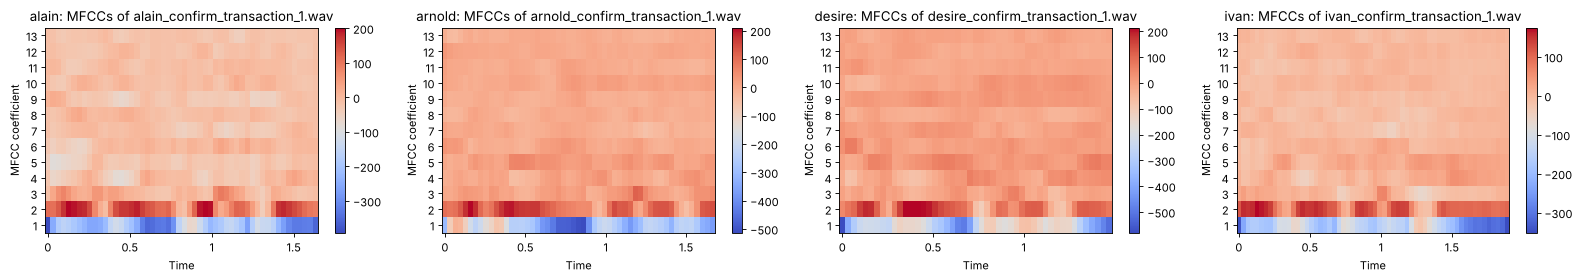

In [9]:
fig, axes = plt.subplots(1, len(members), figsize=(5 * len(members), 3.6), squeeze=False)
for ax, member in zip(axes[0], members):
    row = order[order["member"] == member].iloc[0]
    mfcc = librosa.feature.mfcc(y=clean[row["path"]], sr=SR, n_mfcc=ap.N_MFCC)
    img = librosa.display.specshow(mfcc, sr=SR, x_axis="time", ax=ax, cmap="coolwarm")
    ax.set_yticks(range(ap.N_MFCC))
    ax.set_yticklabels(range(1, ap.N_MFCC + 1))
    ax.set_ylabel("MFCC coefficient")
    ax.set_title(f"{member}: MFCCs of {row['path'].name}")
    fig.colorbar(img, ax=ax)
fig.tight_layout()
plt.show()

## 8. Build and save `audio_features.csv`

One row per (recording, augmentation). Metadata columns come first, followed by the 50 feature columns.

In [10]:
features = ap.build_feature_table()
features.to_csv(ap.OUTPUT_CSV, index=False, float_format="%.6f")

feature_cols = ap.feature_columns(features)
print(f"Saved {ap.OUTPUT_CSV.relative_to(REPO_ROOT)}: {features.shape[0]} rows, "
      f"{len(ap.METADATA_COLUMNS)} metadata columns, {len(feature_cols)} feature columns")
display(features.head(8))

Saved datasets/audio_features.csv: 98 rows, 6 metadata columns, 50 feature columns


,clip_id,member,phrase,take,augmentation,source_clip,duration_s,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,...,spectral_rolloff_mean,spectral_rolloff_std,spectral_centroid_mean,spectral_centroid_std,spectral_bandwidth_mean,spectral_bandwidth_std,rms_energy_mean,rms_energy_std,zcr_mean,zcr_std
0,alain_confirm_transaction_1__original,alain,confirm_transaction,1,original,data/audio/alain/alain_confirm_transaction_1.wav,1.632000,-223.495285,81.956276,112.981781,...,3126.953125,2041.171631,1724.478394,1117.841187,1587.453125,531.944641,0.076639,0.053125,0.151198,0.115733
1,alain_confirm_transaction_1__pitch_up_2st,alain,confirm_transaction,1,pitch_up_2st,data/audio/alain/alain_confirm_transaction_1.wav,1.632000,-235.034775,79.318733,106.365311,...,3474.759521,2136.797363,1855.564575,1019.892639,1751.924683,540.011169,0.054627,0.039586,0.160344,0.116821
2,alain_confirm_transaction_1__pitch_down_2st,alain,confirm_transaction,1,pitch_down_2st,data/audio/alain/alain_confirm_transaction_1.wav,1.632000,-250.966644,78.083740,123.023796,...,2948.617676,1765.461182,1574.622437,856.529053,1524.496094,446.012695,0.057539,0.046082,0.139339,0.100881
3,alain_confirm_transaction_1__time_stretch_fast,alain,confirm_transaction,1,time_stretch_fast,data/audio/alain/alain_confirm_transaction_1.wav,1.419125,-232.544724,79.391571,107.353539,...,3387.673584,1991.022827,1769.963501,916.424011,1743.631104,500.646301,0.056967,0.044210,0.150575,0.101300
4,alain_confirm_transaction_1__time_stretch_slow,alain,confirm_transaction,1,time_stretch_slow,data/audio/alain/alain_confirm_transaction_1.wav,1.920000,-240.771454,80.312607,108.788612,...,3287.013428,2068.293945,1765.637573,1012.133606,1687.707764,527.935669,0.055827,0.041432,0.150703,0.116169
5,alain_confirm_transaction_1__background_noise,alain,confirm_transaction,1,background_noise,data/audio/alain/alain_confirm_transaction_1.wav,1.632000,-148.634735,48.443726,61.471764,...,5025.690918,1681.752197,2536.323730,943.034119,2191.802490,319.258850,0.077527,0.052545,0.220872,0.109821
6,alain_confirm_transaction_1__gain_down_6db,alain,confirm_transaction,1,gain_down_6db,data/audio/alain/alain_confirm_transaction_1.wav,1.632000,-291.377563,81.956261,112.981781,...,3126.953125,2041.171631,1724.478394,1117.841187,1587.453125,531.944641,0.038411,0.026626,0.151198,0.115733
7,alain_confirm_transaction_2__original,alain,confirm_transaction,2,original,data/audio/alain/alain_confirm_transaction_2.wav,1.600000,-188.768173,68.038536,95.845390,...,3744.638428,2039.671753,2020.058228,1161.601807,1776.532837,453.723846,0.096240,0.064651,0.189568,0.129042


In [11]:
# Validation of the saved file
saved = pd.read_csv(ap.OUTPUT_CSV)
checks = {
    "rows = recordings x versions": len(saved) == len(clips) * len(ap.AUGMENTATIONS),
    "no missing values": not saved.isna().any().any(),
    "no infinite values": bool(np.isfinite(saved[feature_cols]).all().all()),
    "unique clip_id": saved["clip_id"].is_unique,
    "every member has both phrases": bool((saved.groupby("member")["phrase"].nunique() == 2).all()),
}
display(pd.Series(checks, name="passed").to_frame())
display(pd.crosstab([saved["member"], saved["phrase"]], saved["augmentation"]))

,passed
rows = recordings x versions,True
no missing values,True
no infinite values,True
unique clip_id,True
every member has both phrases,True


augmentation                background_noise  gain_down_6db  original  pitch_down_2st  pitch_up_2st  time_stretch_fast  time_stretch_slow
member phrase                                                                                                                            
alain  confirm_transaction                 2              2         2               2             2                  2                  2
       yes_approve                         2              2         2               2             2                  2                  2
arnold confirm_transaction                 2              2         2               2             2                  2                  2
       yes_approve                         2              2         2               2             2                  2                  2
desire confirm_transaction                 2              2         2               2             2                  2                  2
       yes_approve                         2              2         2               2             2                  2                  2
ivan   confirm_transaction                 1              1         1               1             1                  1                  1
       yes_approve                         1              1         1               1             1                  1                  1

## 9. How the features differ between members

Original recordings only, so augmentations do not hide the natural spread.

member                         alain   arnold   desire     ivan
mfcc_1_mean            mean  -205.59  -245.39  -217.98  -175.63
                       std     30.59    43.92    25.32     4.44
mfcc_2_mean            mean    95.65   106.03    82.75    81.17
                       std     13.25    10.38    19.98    26.09
mfcc_3_mean            mean    20.00    11.71    -6.20     9.38
                       std      9.88    27.67    16.27    16.72
spectral_centroid_mean mean  1984.66  1666.83  2057.78  2069.72
                       std    220.32   278.10   406.29   618.93
spectral_rolloff_mean  mean  3651.31  3018.80  3680.55  3762.61
                       std    402.20   263.87   743.17   933.02
rms_energy_mean        mean     0.10     0.08     0.08     0.10
                       std      0.03     0.02     0.02     0.02
zcr_mean               mean     0.19     0.12     0.18     0.16
                       std      0.03     0.04     0.05     0.08
duration_s             mean     1.41     1.62     1.27     1.71
                       std      0.33     0.42     0.22     0.25

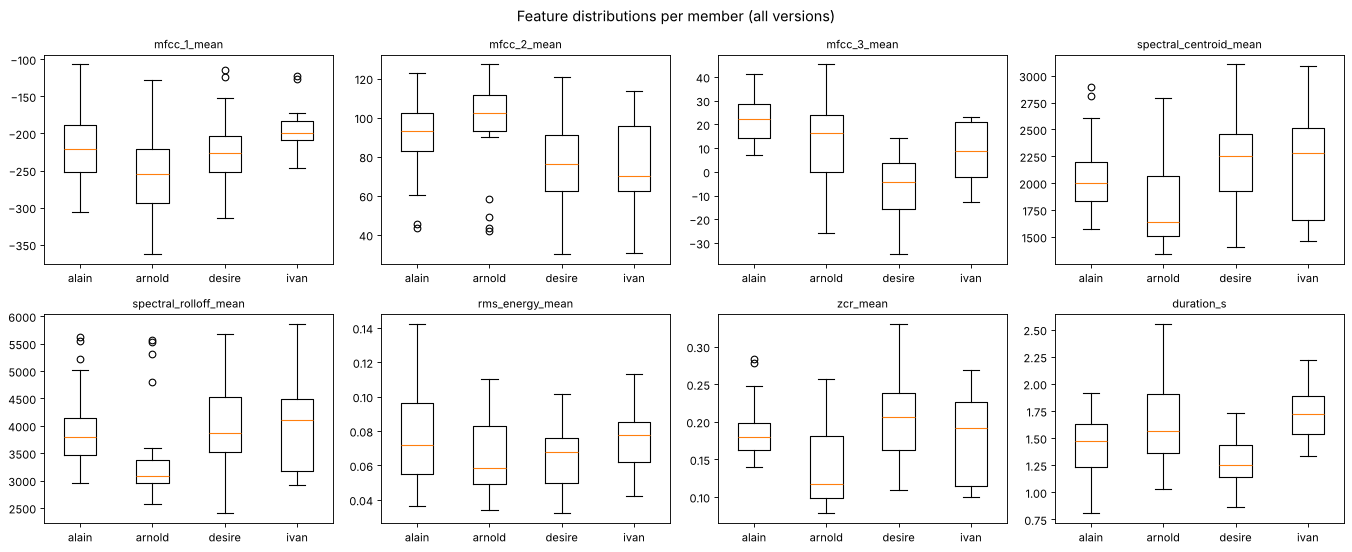

In [12]:
summary_features = ["mfcc_1_mean", "mfcc_2_mean", "mfcc_3_mean", "spectral_centroid_mean",
                    "spectral_rolloff_mean", "rms_energy_mean", "zcr_mean", "duration_s"]
originals = saved[saved["augmentation"] == "original"]
display(originals.groupby("member")[summary_features].agg(["mean", "std"]).round(2).T)

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, col in zip(axes.ravel(), summary_features):
    data = [saved.loc[saved["member"] == m, col] for m in members]
    ax.boxplot(data)
    ax.set_xticks(range(1, len(members) + 1), members)
    ax.set_title(col, fontsize=10)
fig.suptitle("Feature distributions per member (all versions)", fontsize=13)
fig.tight_layout()
plt.show()

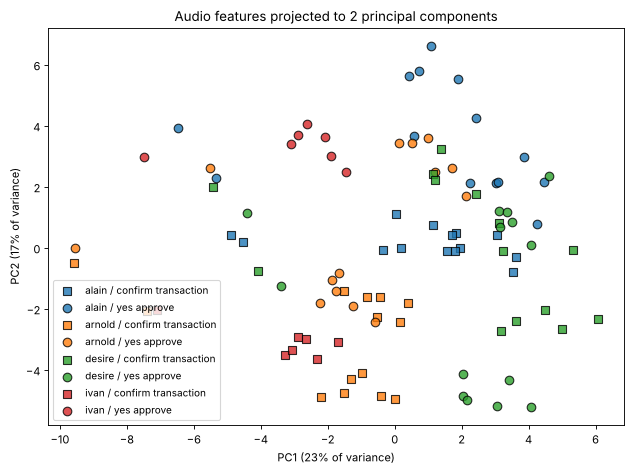

In [13]:
X = StandardScaler().fit_transform(saved[feature_cols])
pca = PCA(n_components=2, random_state=ap.SEED)
coords = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(8, 6))
markers = {"yes_approve": "o", "confirm_transaction": "s"}
colours = dict(zip(members, plt.cm.tab10.colors))
for (member, phrase), idx in saved.groupby(["member", "phrase"]).groups.items():
    ax.scatter(coords[idx, 0], coords[idx, 1], c=[colours[member]], marker=markers.get(phrase, "x"),
               s=60, alpha=0.8, edgecolor="k", label=f"{member} / {phrase.replace('_', ' ')}")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
ax.set_title("Audio features projected to 2 principal components")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

**Identity signal check (not the final model).** Each recording is held out in turn with all 7 of its versions and
labelled with the member of its nearest neighbour among the other recordings. Holding out whole recordings avoids
matching a clip against its own augmented copies.

In [14]:
from sklearn.neighbors import KNeighborsClassifier

correct = 0
for clip in saved["source_clip"].unique():
    train, test = saved[saved["source_clip"] != clip], saved[saved["source_clip"] == clip]
    scaler = StandardScaler().fit(train[feature_cols])
    knn = KNeighborsClassifier(n_neighbors=1).fit(scaler.transform(train[feature_cols]), train["member"])
    correct += (knn.predict(scaler.transform(test[feature_cols])) == test["member"]).sum()
print(f"Leave-one-recording-out accuracy: {correct / len(saved):.2f} (chance level {1 / len(members):.2f})")

Leave-one-recording-out accuracy: 0.58 (chance level 0.25)


**Interpretation:** the first two components explain 40% of the variance (23% + 17%). Desire's versions (green) sit mostly on the right, and Alain's (blue) at the top right for "yes approve" and in the middle for "confirm transaction". Arnold's (orange) and Ivan's (red) both sit on the lower left, and Ivan's "confirm transaction" versions lie right next to Arnold's. That overlap is the hardest case for the voiceprint model. The points furthest left are the `background_noise` versions of every speaker: added noise moves the spectral features more than the change of speaker does, which is exactly why it is a useful augmentation.

In the box plots, `mfcc_3_mean` separates Desire (about -6) from Alain (+20), with Arnold (+12) and Ivan (+9) in between and close to each other. Arnold's low `spectral_centroid_mean`, `spectral_rolloff_mean` and `zcr_mean` (0.12, against 0.16 to 0.19) set his deeper, darker voice apart. Loudness (`rms_energy_mean`) overlaps for everyone, as expected after peak normalisation. The nearest-neighbour check matches 0.58 of held-out versions to the right speaker, against 0.25 by chance with four speakers. It is lower than with three speakers mainly because Ivan has a single recording per phrase: when one is held out, his only remaining example is the *other* phrase, and the nearest match is usually Arnold.

## 10. Summary and notes for the voiceprint model

* **`datasets/audio_features.csv`**: 98 rows (14 recordings x 7 versions: 2 phrases x 2 takes for Alain, Arnold and Desire, 2 phrases x 1 take for Ivan), 6 metadata columns and 50 feature columns (26 MFCC mean and std, 13 MFCC delta std, roll-off, centroid, bandwidth, RMS energy, zero-crossing rate and duration). All validation checks pass.
* **Target column:** `member`. The voiceprint model is trained on both phrases together; `phrase` stays available for analysis.
* **Split by `source_clip`, never by row.** The 7 versions of a recording are near copies, so the voice model uses `GroupKFold` with `groups=source_clip`.
* **Scaling:** standardise the features for Logistic Regression; tree models do not need it.
* **At login time** `ap.features_for_path(path)` turns a new recording of any format into the same 50 features. The voice must belong to the same member the face model recognised, and it is rejected when the model's confidence is below a threshold (see `Formative_2_Models_and_System_Demo.ipynb`).
* **Known device bias:** each member used a different phone, and Desire's phone removed background noise. A model could partly learn which phone was used rather than whose voice it is. For the unauthorised-attempt demo, record the stranger's voice on one of the team's own phones, so the test is about the voice and not the device.
* **Limitations:** 2 to 4 recordings per member is very little, and **Ivan needs a second take of each phrase**: with one take, his voice is hard to tell from Arnold's. More takes, ideally on the same phone for everyone, would make the voiceprint model more reliable.